# Math 50 HW2
## Jack Chou


### Load Data

In [111]:
# Loads the Gaza and Ukraine casualty datasets for Math 50 Assignment 2
# into dataframes `gaza` and `ukraine`. Data is loaded directly from
# math50-data (raw GitHub URLs), so this notebook runs as-is in Colab.

# Load Script Source: Ethan Levien

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [112]:
GAZA_URL = "https://raw.githubusercontent.com/elevien/math50-data/main/data/gaza-casualties.csv"
UKRAINE_URL = "https://raw.githubusercontent.com/elevien/math50-data/main/data/ukraine-personnel-losses.csv"

BURN = 300  # drop the first 300 days: low, volatile early counts
GAZA_CEASEFIRE = pd.Timestamp("2025-10-10")


def load_gaza():
    # columns: time, counts (cumulative), daily (day-over-day increment),
    # period ("before"/"after" the ceasefire, in place of truncating),
    # plus a few of the other reported sub-counts
    df = pd.read_csv(GAZA_URL, parse_dates=["report_date"])
    counts = df["ext_killed_cum"].to_numpy().astype(float)
    daily = np.empty(len(counts))
    daily[0] = np.nan
    daily[1:] = counts[1:] - counts[:-1]

    period = np.empty(len(df), dtype=object)
    before = (df["report_date"] <= GAZA_CEASEFIRE).to_numpy()
    period[before] = "before"
    period[~before] = "after"

    out = pd.DataFrame({
        "time": df["report_date"],
        "counts": counts,
        "daily": daily,
        "period": period,
        "children_killed_cum": df["ext_killed_children_cum"].to_numpy(),
        "women_killed_cum": df["ext_killed_women_cum"].to_numpy(),
        "injured_cum": df["ext_injured_cum"].to_numpy(),
    })
    return out.iloc[BURN + 1:].reset_index(drop=True)


def load_ukraine():
    # columns: time, counts (cumulative), daily (day-over-day increment), POW
    df = pd.read_csv(UKRAINE_URL, parse_dates=["date"])
    counts = df["personnel"].to_numpy().astype(float)
    daily = np.empty(len(counts))
    daily[0] = np.nan
    daily[1:] = counts[1:] - counts[:-1]

    out = pd.DataFrame({
        "time": df["date"],
        "counts": counts,
        "daily": daily,
        "POW": df["POW"].to_numpy(),
    })
    return out.iloc[BURN + 1:].reset_index(drop=True)


gaza = load_gaza()
ukraine = load_ukraine()
gaza

,time,counts,daily,period,children_killed_cum,women_killed_cum,injured_cum
0,2024-08-03,39550.0,31.0,before,16314,10980,91280
1,2024-08-04,39583.0,33.0,before,16314,10980,91398
2,2024-08-05,39623.0,40.0,before,16314,10980,91469
3,2024-08-06,39653.0,30.0,before,16365,11012,91535
4,2024-08-07,39677.0,24.0,before,16365,11012,91645
...,...,...,...,...,...,...,...
776,2026-09-18,73821.0,0.0,after,20179,12500,174897
777,2026-09-19,73910.0,89.0,after,20179,12500,174914
778,2026-09-20,73910.0,0.0,after,20179,12500,174935
779,2026-09-21,73914.0,4.0,after,20179,12500,174952


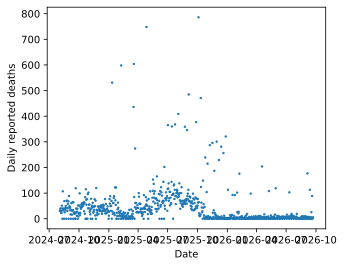

In [113]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(gaza.time, gaza.daily, ".", markersize=3)
ax.set_xlabel("Date")
ax.set_ylabel("Daily reported deaths")
plt.show()

In [114]:
ukraine

,time,counts,daily,POW
0,2022-12-23,100950.0,550.0,NaN
1,2022-12-24,101430.0,480.0,NaN
2,2022-12-25,102050.0,620.0,NaN
3,2022-12-26,102600.0,550.0,NaN
4,2022-12-27,103220.0,620.0,NaN
...,...,...,...,...
1365,2026-09-18,1514910.0,1420.0,NaN
1366,2026-09-19,1516430.0,1520.0,NaN
1367,2026-09-20,1517990.0,1560.0,NaN
1368,2026-09-21,1519650.0,1660.0,NaN


## Problem 1: Parsing Wyner's Argument

### 1.1 Wyner's two main observations

1. The daily totals are too regular. Wyner writes that "the daily reported casualty count over this period averages 270 plus or minus about 15%" and that "there should be days with twice the average or more and others with half or less." He also says the graph of total deaths is "increasing with almost metronomical linearity" (Figure 1).
2. The breakdown by group does not behave like real data. Women and children counts are not correlated: "R2 is .017 which is statistically and substantively not different from 0." Men and women are strongly negatively correlated: "there is a strong negative correlation, which makes no sense at all."

From these he concludes that "a process unconnected or loosely connected to reality was used to report the numbers." He adds some smaller anomalies, such as the Oct. 28 to Oct. 29 reports implying that "26 men came back to life."

In [115]:
# Helper functions
rng = np.random.default_rng(42)


# R^2 of a simple linear regression of y on x, squared correlation coefficient
def r2(x, y):
    return np.corrcoef(x, y)[0, 1] ** 2

# coefficient of variation: standard deviation divided by the mean
def cv(x):
    return np.std(x, ddof=1) / np.mean(x)

# returns SS_res and SS_tot for the regression of y on x
def ss_parts(x, y):
    slope, intercept = np.polyfit(x, y, 1)
    resid = y - (slope * x + intercept)
    ss_res = np.sum(resid ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    return ss_res, ss_tot

The first block rebuilds Wyner's own window from the raw data. The CV is close to his (about 15%), but the other statistics are not identical (his women vs children R2 is .017 and his men vs women correlation is -0.91, read off his men vs women figure; this window's R2 and correlations are in the figure titles below). The source here is the Tech for Palestine compilation and he used a different one. In particular the men vs women correlation here is only about -0.4, and the men's count is near 0 on one day, where his figure shows three.

In [116]:
# The loader above drops the first 300 days, so Wyner's window is not in the `gaza` dataframe
# Read the raw file again and keep Oct 26 to Nov 10, 2023.
raw = pd.read_csv(GAZA_URL, parse_dates=["report_date"])
win = raw[(raw.report_date >= "2023-10-26") & (raw.report_date <= "2023-11-10")]

# 16 cumulative reports give 15 daily increments
N = np.diff(win.ext_killed_cum.to_numpy().astype(float)) # everyone
C = np.diff(win.ext_killed_children_cum.to_numpy().astype(float)) # children
F = np.diff(win.ext_killed_women_cum.to_numpy().astype(float)) # women
M = N - C - F # men, as Wyner defines it
day = np.arange(len(N))

print("days:", len(N))
print("mean daily total:", N.mean().round(1))
print("sd of daily total:", N.std(ddof=1).round(1))
print("CV of daily total:", cv(N).round(3))

# share of each day's total that is women / children
print("women's share of daily total: min", (F / N).min().round(2), "max", (F / N).max().round(2))
print("children's share of daily total: min", (C / N).min().round(2), "max", (C / N).max().round(2))

days: 15
mean daily total: 270.0
sd of daily total: 44.8
CV of daily total: 0.166
women's share of daily total: min 0.14 max 0.5
children's share of daily total: min 0.0 max 0.52


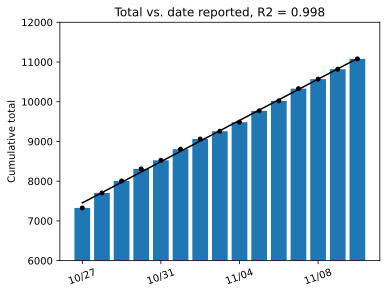

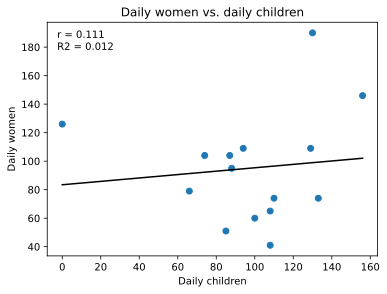

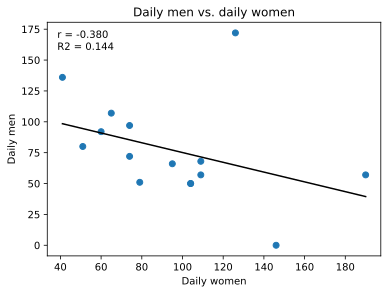

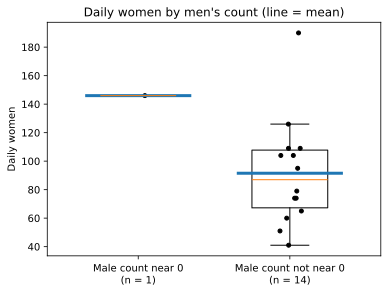

men's count by day: [172.  57.   0.  97.  80. 107.  72.  51.  50. 136.  92.  68.  50.  66.
  57.]
days with men near 0: 1 | women on those days: [146.]
mean women, near 0 vs not near 0: 146.0 91.5
rank of women's count on near-0 days (1 = highest): [2]


In [117]:
# Wyner's four figures from the real window: cumulative total, women vs children,
# men vs women, and women on the days when the men's count is near 0 vs the other days.
cum_r = win.ext_killed_cum.to_numpy()[1:]               # reported cumulative total, one per day
dates_r = win.report_date.dt.strftime("%m/%d").to_numpy()[1:]

t = np.arange(len(cum_r))
near0 = M < 0.25 * np.mean(M)   # "near 0": men's count below a quarter of its average

# Figure 1: cumulative reported total with a fitted line
fig, ax = plt.subplots(figsize=(5.5, 4.2))
s, b = np.polyfit(t, cum_r, 1)
ax.bar(t, cum_r - 6000, bottom=6000, color="C0")
ax.plot(t, cum_r, "ko", markersize=4)
ax.plot(t, s * t + b, "k-")
ax.set_ylim(6000, 12000)
ax.set_xticks(t[::4])
ax.set_xticklabels(dates_r[::4], rotation=20)
ax.set_title(f"Total vs. date reported, R2 = {r2(t, cum_r):.3f}")
ax.set_ylabel("Cumulative total")
plt.tight_layout()
plt.show()

# Figure 2: daily women (y) vs daily children (x)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
s, b = np.polyfit(C, F, 1)
xs = np.array([C.min(), C.max()])
ax.plot(C, F, "o", color="C0")
ax.plot(xs, s * xs + b, "k-")
ax.text(0.03, 0.97, f"r = {np.corrcoef(C, F)[0, 1]:.3f}\nR2 = {r2(C, F):.3f}",
        transform=ax.transAxes, va="top")
ax.set_xlabel("Daily children")
ax.set_ylabel("Daily women")
ax.set_title("Daily women vs. daily children")
plt.tight_layout()
plt.show()

# Figure 3: daily men (y) vs daily women (x)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
s, b = np.polyfit(F, M, 1)
xs = np.array([F.min(), F.max()])
ax.plot(F, M, "o", color="C0")
ax.plot(xs, s * xs + b, "k-")
ax.text(0.03, 0.97, f"r = {np.corrcoef(F, M)[0, 1]:.3f}\nR2 = {r2(F, M):.3f}",
        transform=ax.transAxes, va="top")
ax.set_xlabel("Daily women")
ax.set_ylabel("Daily men")
ax.set_title("Daily men vs. daily women")
plt.tight_layout()
plt.show()

# Figure 4: daily women on days when the men's count is near 0 vs not near 0
fig, ax = plt.subplots(figsize=(5.5, 4.2))
for k, g in enumerate([F[near0], F[~near0]]):
    if len(g) == 0:
        continue
    ax.boxplot(g, positions=[k], widths=0.5, showfliers=False)
    ax.plot(k + rng.uniform(-0.08, 0.08, len(g)), g, "ko", markersize=4)
    ax.hlines(g.mean(), k - 0.35, k + 0.35, color="C0", lw=3)
ax.set_xticks([0, 1])
ax.set_xticklabels([f"Male count near 0\n(n = {near0.sum()})", f"Male count not near 0\n(n = {(~near0).sum()})"])
ax.set_xlim(-0.6, 1.6)
ax.set_ylabel("Daily women")
ax.set_title("Daily women by men's count (line = mean)")
plt.tight_layout()
plt.show()

print("men's count by day:", M)
print("days with men near 0:", near0.sum(), "| women on those days:", F[near0])
print("mean women, near 0 vs not near 0:", F[near0].mean().round(1), F[~near0].mean().round(1))
print("rank of women's count on near-0 days (1 = highest):", [int((F > f).sum() + 1) for f in F[near0]])

### 1.2 Wyner's observations as probability statements

Let $N_i = M_i + F_i + C_i$ be the total on day $i$, where $M_i$ is men, $F_i$ is women and $C_i$ is children.

1. Low variation. "270 plus or minus about 15%" means $SD(N_i)/E[N_i] \approx 0.15$, so $P(N_i \ge 2E[N_i])$ and $P(N_i \le E[N_i]/2)$ are close to 0. Wyner thinks both should be clearly positive for real data.
2. No correlation between women and children. "R2 is .017" means $Corr(F_i, C_i)^2 \approx 0.017$. Wyner thinks $Corr(F_i, C_i)$ should be clearly positive, because the same strikes drive both counts.
3. Men and women are negatively correlated. "A strong negative correlation" means $Corr(M_i, F_i) < 0$. Wyner thinks it should be positive, for the same reason as point 2.
4. Women are high when men are near 0 (this is not one of the three main observations; it is the one behind Wyner's box plot). On the days when the men's count is near 0, "the women's count is high." This says $E[F_i \mid M_i \approx 0] > E[F_i \mid M_i \not\approx 0]$. If those near-0 days were just reporting errors in the men's count, Wyner expects the two means to be equal.

His story adds a further statement: about 70% of the total is women and children, so $E[(F_i + C_i)/N_i] \approx 0.7$, with a random split between $F_i$ and $C_i$ and men as the rest.

The simulation below follows that story. Then I remake his four plots: the cumulative total, women vs children, men vs women and the box plot of women by whether the men's count is near 0.

**Assumptions and modeling choices.**

- Daily totals are Normal(270, 42), so the CV is about .15. Since a death count can't be negative, I clip / set a floor at 0 and use real numbers instead of counts.
- Days are independent, with no trend or weekly cycle.
- The share of women is Uniform(0.15, 0.50) and the share of children is Uniform(0.20, 0.55), independent of each other and of the total. Together they average about 70%. Men are the remainder. These ranges roughly match the real window, where the women's share of the daily total runs from 0.14 to 0.50 and the children's from 0 to 0.52 (printed above).
- 15 days, fixed random seed.
- "Near 0" for men is a count below a quarter of the average men's count. Wyner does not give a cutoff, so this is my choice, used for both the real and the simulated data.
- The plot of the cumulative total uses the reported cumulative totals (not the sum from zero), and the simulated one starts from the real window's first report so the axes match.

I use independent shares because splitting a fixed 70% between women and children would force a negative correlation between them.

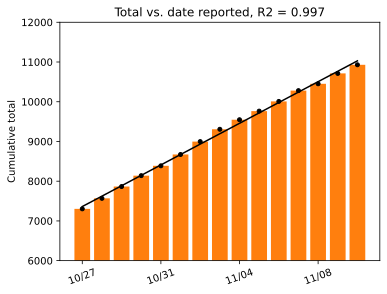

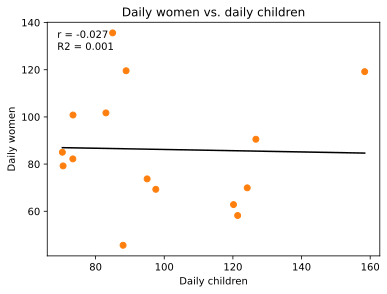

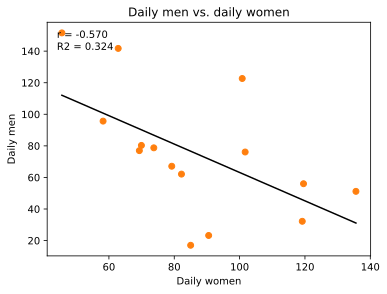

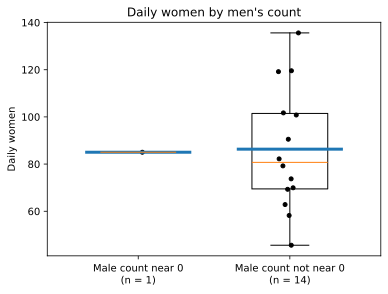

days with men near 0: 1 | women on those days: [85.]
mean women, near 0 vs not near 0: 85.0 86.3
share of simulated windows with at least one near-0 men day: 0.648


,mean,5%,95%
CV of daily total,0.153,0.107,0.205
R2 cumulative vs day,0.999,0.997,1.000
R2 women vs children,0.111,0.001,0.383
corr men vs women,-0.460,-0.754,-0.085
women: near-0 days minus other days,34.333,0.872,70.247


In [118]:
def simulate_wyner(n=15, mean=270, sd=42, gen=None):
    gen = rng if gen is None else gen
    N_sim = np.clip(gen.normal(mean, sd, n), 0, None) # daily totals, real numbers
    a = gen.uniform(0.15, 0.50, n) # share that are women
    b = gen.uniform(0.20, 0.55, n) # share that are children
    F_sim = N_sim * a
    C_sim = N_sim * b
    M_sim = N_sim - F_sim - C_sim # men fill in the rest
    return N_sim, F_sim, C_sim, M_sim


N_s, F_s, C_s, M_s = simulate_wyner()
# The box plot needs at least one day with men near 0, which about 65% of windows have (see below).
# If this draw has none, redraw from a separate generator so the later cells keep the same random stream.
g = np.random.default_rng(0)
while not (M_s < 0.25 * M_s.mean()).any():
    N_s, F_s, C_s, M_s = simulate_wyner(gen=g)
d_s = np.arange(15)

# start the cumulative total at the real window's first report so the axes match
cum_s = win.ext_killed_cum.iloc[0] + np.cumsum(N_s)
dates_s = win.report_date.dt.strftime("%m/%d").to_numpy()[1:]

t = np.arange(len(cum_s))
near0_s = M_s < 0.25 * np.mean(M_s) # "near 0": men's count below a quarter of its average

# Figure 1: cumulative reported total with a fitted line
fig, ax = plt.subplots(figsize=(5.5, 4.2))
s, b = np.polyfit(t, cum_s, 1)
ax.bar(t, cum_s - 6000, bottom=6000, color="C1")
ax.plot(t, cum_s, "ko", markersize=4)
ax.plot(t, s * t + b, "k-")
ax.set_ylim(6000, 12000)
ax.set_xticks(t[::4])
ax.set_xticklabels(dates_s[::4], rotation=20)
ax.set_title(f"Total vs. date reported, R2 = {r2(t, cum_s):.3f}")
ax.set_ylabel("Cumulative total")
plt.tight_layout()
plt.show()

# Figure 2: daily women (y) vs daily children (x)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
s, b = np.polyfit(C_s, F_s, 1)
xs = np.array([C_s.min(), C_s.max()])
ax.plot(C_s, F_s, "o", color="C1")
ax.plot(xs, s * xs + b, "k-")
ax.text(0.03, 0.97, f"r = {np.corrcoef(C_s, F_s)[0, 1]:.3f}\nR2 = {r2(C_s, F_s):.3f}",
        transform=ax.transAxes, va="top")
ax.set_xlabel("Daily children")
ax.set_ylabel("Daily women")
ax.set_title("Daily women vs. daily children")
plt.tight_layout()
plt.show()

# Figure 3: daily men (y) vs daily women (x)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
s, b = np.polyfit(F_s, M_s, 1)
xs = np.array([F_s.min(), F_s.max()])
ax.plot(F_s, M_s, "o", color="C1")
ax.plot(xs, s * xs + b, "k-")
ax.text(0.03, 0.97, f"r = {np.corrcoef(F_s, M_s)[0, 1]:.3f}\nR2 = {r2(F_s, M_s):.3f}",
        transform=ax.transAxes, va="top")
ax.set_xlabel("Daily women")
ax.set_ylabel("Daily men")
ax.set_title("Daily men vs. daily women")
plt.tight_layout()
plt.show()

# Figure 4: daily women on days when the men's count is near 0 vs not near 0
fig, ax = plt.subplots(figsize=(5.5, 4.2))
for k, g in enumerate([F_s[near0_s], F_s[~near0_s]]):
    if len(g) == 0:
        continue
    ax.boxplot(g, positions=[k], widths=0.5, showfliers=False)
    ax.plot(k + rng.uniform(-0.08, 0.08, len(g)), g, "ko", markersize=4)
    ax.hlines(g.mean(), k - 0.35, k + 0.35, color="C0", lw=3)
ax.set_xticks([0, 1])
ax.set_xticklabels([f"Male count near 0\n(n = {near0_s.sum()})", f"Male count not near 0\n(n = {(~near0_s).sum()})"])
ax.set_xlim(-0.6, 1.6)
ax.set_ylabel("Daily women")
ax.set_title("Daily women by men's count")
plt.tight_layout()
plt.show()

print("days with men near 0:", near0_s.sum(), "| women on those days:", F_s[near0_s].round(0))
print("mean women, near 0 vs not near 0:",
      F_s[near0_s].mean().round(1) if near0_s.any() else None, F_s[~near0_s].mean().round(1))

# One draw can be unlucky, so repeat 2000 times and look at the spread
out = []
for _ in range(2000):
    n_, f_, c_, m_ = simulate_wyner()
    z_ = m_ < 0.25 * m_.mean()
    gap = f_[z_].mean() - f_[~z_].mean() if z_.any() else np.nan
    out.append([cv(n_), r2(d_s, np.cumsum(n_)), r2(f_, c_), np.corrcoef(m_, f_)[0, 1], gap])
out = np.array(out)
summary = pd.DataFrame(
    {"mean": np.nanmean(out, 0), "5%": np.nanpercentile(out, 5, axis=0), "95%": np.nanpercentile(out, 95, axis=0)},
    index=["CV of daily total", "R2 cumulative vs day", "R2 women vs children", "corr men vs women",
           "women: near-0 days minus other days"],
)
print("share of simulated windows with at least one near-0 men day:", np.mean(~np.isnan(out[:, 4])).round(3))
summary.round(3)

In the single draw plotted above, the one day with men near 0 has an ordinary women's count (85 against a mean of 86.3 on the other days), so that box plot does not show observation 4. Across the 2000 simulated windows it does. The women's count on near-0 days is about 34 higher on average (last row of the table). Note that our code says that the simulated correlation is on average -0.46 (see corr men vs women mean), but Wyner's was -0.91 in his figure. This is because for the assumptions, we set the centers to give 70% average, but the widths were based off of the data observed in q1.1. (women/child share of daily total)

## Problem 2: Regression on Cumulative vs Daily Deaths

### 2.1 Why a cumulative process correlates strongly with time

$R^2 = 1 - SS_{R}/SS_{tot}$, where $SS_R$ is the sum of squared residuals and $SS_{tot}$ is the total variation of the response.

A cumulative sum $y_i = x_1 + \dots + x_i$ climbs by about the mean $\mu$ each day, so it spans a range of about $\mu n$ and $SS_{tot} \approx \mu^2 n^3 / 12$. The residuals only hold the leftover noise, which is about the size of the noise in the daily counts. So $SS_R / SS_{tot}$ is tiny, and any count series with a positive mean gets $R^2$ close to 1 once accumulated. This says nothing about whether the numbers are real.

The code below shows this for Wyner's window. $SS_R$ is the same order for both series but $SS_{tot}$ is huge for the cumulative one.

In [119]:
# SS_res and SS_tot for daily counts vs cumulative counts
# Use the real Wyner window first
for name, y in [("daily total x_i", N), ("cumulative total y_i", np.cumsum(N))]:
    ss_res, ss_tot = ss_parts(day, y)
    print(f"{name:22s} SS_res = {ss_res:.3f}   SS_tot = {ss_tot:.3f}   R2 = {1 - ss_res / ss_tot:.3f}") #Round to 3 dcml place

daily total x_i        SS_res = 22591.711   SS_tot = 28092.000   R2 = 0.196
cumulative total y_i   SS_res = 33685.558   SS_tot = 18907124.933   R2 = 0.998


### 2.2 The Pachter comment and the Gelman rule for good science

Pachter writes that "when one starts floating tons of hypotheses, especially with little data, evidence for one of them doesn't carry significance." This is the garden of forking paths (item 2, researcher degrees of freedom) from the Gelman post "7 steps to junk science": if you may look for any anomaly, you will find one. His example is that the average of the 15 daily counts is a whole number (270), which happens only about 7% of the time. It looks surprising only because we noticed it after the fact.

I mostly agree that it applies here for three reasons.

- Wyner looked at one 15-day window, and commenters say nearby dates are less regular. The window choice is a forking path.
- He ran several tests (CV, women vs children, men vs women, the "men came back to life" day) with no adjustment for multiple comparisons.
- He admits "verified control data is not available," so there was no baseline for what regular means.

### 2.3 "Not the abundance of anomalies but their inherent contradictions"

The commenter has a fair point. If the numbers came from one clean process, women, children and men should all move together, so no link or a negative link looks contradictory. But this only holds if all three counts are measured the same way on the same day. Other explanations are plausible.

- Totals come from the Ministry and women and children counts from the Media Office, at different times of day.
- Identifying women and children needs name records, so these counts may be updated in bunches while totals are updated daily.
- Since number of men killed is calculated as $M_i = N_i - F_i - C_i$, if women are not updated on a day, the number of men will look high. If women are updated in a big batch, men look low. This creates a negative correlation by construction.
- With 15 days the correlation estimates are very noisy (see the 5% to 95% range above).
- Reporting in the north stopped in November, in the middle of Wyner's window.

## Problem 3: Examining Real Data

### 3.1 Random windows with the same length as Wyner's

Wyner used 15 days. I sample many random 15-day windows and compute the CV and the cumulative $R^2$ for each. The Gaza data has three parts. The first 300 days (which the loader drops), the later war period before the ceasefire, and the period after the ceasefire. I use the first two and Ukraine.

In [120]:
# Only the "before ceasefire" part of Gaza is used, to match Wyner's war-time setting.
gaza_before = gaza[gaza.period == "before"].reset_index(drop=True)
print("Gaza (before) days:", len(gaza_before), " Ukraine days:", len(ukraine))


def window_stats(daily, n_windows=2000, length=15):
    # pick random start days, then compute CV and cumulative R2 for each window
    daily = np.asarray(daily, dtype=float)
    starts = rng.integers(0, len(daily) - length, n_windows)
    t = np.arange(length)
    cvs, r2s = [], []
    for s in starts:
        x = daily[s:s + length]
        cvs.append(cv(x))
        r2s.append(r2(t, np.cumsum(x)))
    return np.array(cvs), np.array(r2s)


# The first 300 days were dropped by the loader, so rebuild them from the raw file.
early = raw.iloc[:301]
early_daily = np.diff(early.ext_killed_cum.to_numpy().astype(float))

cv_g, r2_g = window_stats(gaza_before.daily)
cv_e, r2_e = window_stats(early_daily)
cv_u, r2_u = window_stats(ukraine.daily)

def row(c, r):
    # four summary numbers for one series of windows
    return [np.median(c), np.mean(c <= cv(N)), np.median(r), np.mean(r >= r2(day, np.cumsum(N)))]


table = pd.DataFrame({
    "Gaza (first 300 days)": row(cv_e, r2_e),
    "Gaza (before)": row(cv_g, r2_g),
    "Ukraine": row(cv_u, r2_u),
}, index=["median CV", "share of windows with CV <= Wyner's", "median R2 (cumulative)", "share with R2 >= Wyner's"])
table.round(3)

Gaza (before) days: 434  Ukraine days: 1370


,Gaza (first 300 days),Gaza (before),Ukraine
median CV,0.334,0.716,0.134
share of windows with CV <= Wyner's,0.052,0.000,0.710
median R2 (cumulative),0.993,0.974,0.999
share with R2 >= Wyner's,0.086,0.000,0.652


**Results:**

- In the first 300 days of Gaza data, about 5% of windows are as regular as Wyner's (CV at or below his). His window is on the regular end but not impossible.
- In the later war period (before the ceasefire) no window is that regular. The median CV is above .7 and some days are 0, because numbers come in lumps (weekly updates and corrections).
- Ukraine windows are *more* regular than Wyner's. The median CV is about .13 and most windows have CV below his.

So random Gaza windows do not usually give Wyner's result, but the same low CV and high cumulative $R^2$ appear in a data set nobody calls fake.

Next I check women vs children. After the burn-in the women and children counts change on only about 5% of days (about a third of days in the first 300 days), so I use the first 300 days.

In [121]:
# Women vs children R2 over random 15-day windows of the first 300 days.
# Many windows have days with no update, so these R2 values are rough.
Fe = np.diff(early.ext_killed_women_cum.to_numpy().astype(float))
Ce = np.diff(early.ext_killed_children_cum.to_numpy().astype(float))
Ne = np.diff(early.ext_killed_cum.to_numpy().astype(float))
Me = Ne - Fe - Ce

vals = []
for s in rng.integers(0, len(Fe) - 15, 2000): # random start day; windows overlap, so ~285 distinct windows
    f, c, m = Fe[s:s + 15], Ce[s:s + 15], Me[s:s + 15] # women, children, men (men = total - women - children)
    # skip windows where a series is constant, since the correlation is undefined
    if f.std() > 0 and c.std() > 0 and m.std() > 0:
        vals.append([r2(f, c), np.corrcoef(m, f)[0, 1]])  # the two statistics Wyner reports
vals = np.array(vals)
print("windows used:", len(vals))
print("median R2 women vs children:", np.median(vals[:, 0]).round(3))
print("share with R2 <= 0.017:", np.mean(vals[:, 0] <= 0.017).round(3))
print("median corr men vs women:", np.median(vals[:, 1]).round(3))
print("share with corr <= -0.4:", np.mean(vals[:, 1] <= -0.4).round(3))

windows used: 2000
median R2 women vs children: 0.811
share with R2 <= 0.017: 0.038
median corr men vs women: -0.916
share with corr <= -0.4: 0.841


Women vs children is the part of Wyner's analysis that holds up best. Only about 4% of windows have an R2 as low as .017, and the median R2 is about .8, partly because women and children counts are often updated on the same days. The men vs women correlation is very often strongly negative, so Wyner's window is not unusual there. This matches the leftover effect from Problem 2.

### 3.2 Correlation of daily deaths $t$ days apart

I plot $\rho_t$ against the lag $t$ in days. Raw data are in the top row. The bottom row subtracts a 15-day rolling mean to remove slow changes in the level. The gray band is a rough 95% band if there were no correlation.

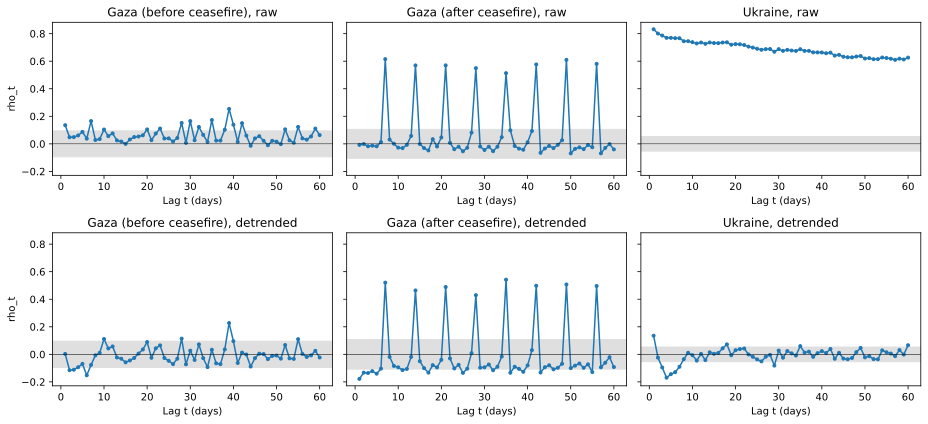

In [122]:
# Problem 3.2: rho_t = correlation of daily deaths with deaths t days later
def rho(x, max_lag=60):
    x = np.asarray(x, dtype=float)
    return np.array([np.corrcoef(x[:-t], x[t:])[0, 1] for t in range(1, max_lag + 1)])


def detrend(x, k=15):
    # subtract a centred rolling mean to remove slow changes in the level
    s = pd.Series(np.asarray(x, dtype=float))
    return (s - s.rolling(k, center=True).mean()).dropna().to_numpy()


series = {
    "Gaza (before ceasefire)": gaza_before.daily.to_numpy(),
    "Gaza (after ceasefire)": gaza[gaza.period == "after"].daily.to_numpy(),
    "Ukraine": ukraine.daily.to_numpy(),
}

fig, ax = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
lags = np.arange(1, 61)
for j, (name, x) in enumerate(series.items()):
    for i, (label, y) in enumerate([("raw", x), ("detrended", detrend(x))]):
        ax[i, j].plot(lags, rho(y), "o-", markersize=3)
        band = 1.96 / np.sqrt(len(y))   # rough 95% band if there were no correlation
        ax[i, j].axhspan(-band, band, color="gray", alpha=0.25)
        ax[i, j].axhline(0, color="k", lw=0.5)
        ax[i, j].set_title(f"{name}, {label}")
        ax[i, j].set_xlabel("Lag t (days)")
ax[0, 0].set_ylabel("rho_t")
ax[1, 0].set_ylabel("rho_t")
plt.tight_layout()
plt.show()

- **Gaza before the ceasefire.** $\rho_t$ is small at almost every lag (mostly below .15 with one bump near .25 at lag 39). Days are close to independent.
- **Gaza after the ceasefire.** There are sharp spikes at $t = 7, 14, 21, \dots$ (about .5 to .6). This is a weekly reporting cycle, not a weekly cycle of deaths.
- **Ukraine, raw.** $\rho_t$ starts at about .8 and decays very slowly. The level of daily losses drifts over months, so nearby days look alike. After removing the trend, $\rho_t$ is near 0 for all lags.

So in all three series, day-to-day noise is nearly independent. Ukraine has a slowly moving level on top and Gaza has reporting rhythms on top.

### 3.3 The Ukraine data set

First a summary table. The plot after it shows the day-of-week pattern.

In [123]:
def summarize(x):
    x = np.asarray(x, dtype=float)
    t = np.arange(len(x))
    return {
        "days": len(x),
        "mean": x.mean(),
        "CV": cv(x),
        "variance / mean": x.var(ddof=1) / x.mean(),
        "R2 cumulative vs day": r2(t, np.cumsum(x)),
        "lag-1 rho": np.corrcoef(x[:-1], x[1:])[0, 1],
    }


pd.DataFrame({name: summarize(x) for name, x in series.items()}).round(3)

,Gaza (before ceasefire),Gaza (after ceasefire),Ukraine
days,434.000,347.000,1370.000
mean,63.806,19.331,1036.847
CV,1.386,2.889,0.310
variance / mean,122.559,161.358,99.867
R2 cumulative vs day,0.964,0.859,0.991
lag-1 rho,0.135,-0.007,0.832


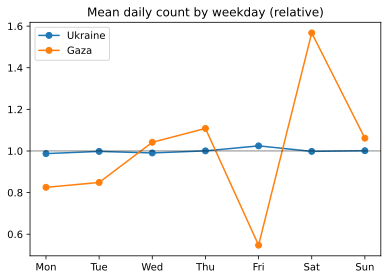

In [124]:
# Does the day of the week matter? Gaza and Ukraine side by side
u_dow = ukraine.groupby(ukraine.time.dt.dayofweek).daily.mean()
g_dow = gaza_before.groupby(gaza_before.time.dt.dayofweek).daily.mean()

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(u_dow.index, u_dow / u_dow.mean(), "o-", label="Ukraine")
ax.plot(g_dow.index, g_dow / g_dow.mean(), "o-", label="Gaza")
ax.axhline(1, color="k", lw=0.5)
ax.set_xticks(range(7))
ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_title("Mean daily count by weekday (relative)")
ax.legend()
plt.tight_layout()
plt.show()

**Differences**

- Ukraine is much larger (mean about 1000 per day vs about 64) and much more regular (CV .31 vs 1.4 for Gaza before the ceasefire).
- Ukraine has a strong trend and a slow-changing level. The lag-1 $\rho$ is .83 vs .14 for Gaza.
- Ukraine has no weekday pattern. Gaza has a big Friday dip and Saturday jump, which points to reporting schedules.
- Ukraine has no ceasefire and no batching spikes at lag 7.

**Similarities**

- Both are overdispersed. The variance is about 100 times the mean or more, where a Poisson count would have 1.
- Both have a very high cumulative $R^2$ (.96 and .99).
- Both are compiled from one side's reports and cannot be independently checked.

Ukraine's windows are even more regular than Wyner's. If low CV proved fabrication, Ukraine would be flagged more strongly, so either those numbers are also made up or the test is not specific. I cannot say which from the data alone, so Ukraine is not a clean control.

## Problem 4: Reflection

After answering these questions, I think Wyner's argument is weaker than it first looked. Two of Wyner's four points fail. **1)** The straight line means nothing, since any cumulative count gives an $R^2$ near 1 (0.998, against 0.196 for the daily counts). **2)** The men vs women correlation is ordinary too. Men are whatever is left after women and children, and random windows have a median of -0.92. But some interesting observations are **1)** only about 5% of random windows from the first 300 days are as regular as his, and none from the later war period are. Also, **2)** only about 4% have a women vs children $R^2$ as low as his 0.017, when the median is about 0.8. Wyner also selected his own window after observing the data, and not drawing his time window at random. He says it is the period when daily breakdowns were available, but he analysed a single 15-day window and chose which statistics to report after seeing the data, which can introduce selection bias.
 
This changes my view of the daily figures. Nothing in our analysis shows the overall death toll is wrong, but the weekly reporting spikes with the women / children counts could suggest that the daily numbers are not direct counts. Hence, I think statistics belongs in discussions, as a reason not to treat the daily figures as verified and not as proof of fabrication, and a useful next step would be to compare the daily totals with the named casualty lists and with verified counts from other conflicts.

The U.S. House of Representatives voted not to cite data from the Gaza Health Ministry. I do not think this analysis supports that vote by itself. It gives reasons to be careful with the daily figures and the women / children breakdown, but it does not show that the totals are made up, and Ukraine's numbers would fail Wyner's regularity test even more.

## LLM Statement 

Model Used: Sonnet 5.5 in Claude Chat.

I used Claude to build a conceptual understanding of three topics. The first was the garden of forking paths from the Gelman reading and how it applies to choosing a window and tests after seeing the data. The second was SSR and SST, and why a cumulative count gets an $R^2$ near 1 even when the daily counts do not. The third was how to look at time series data, including the correlation between days a fixed lag apart and how to separate a slow trend from day-to-day noise. The code is more complex than last time, so I also had Claude refine my graph code (layout, labels and titles for the multi-panel figures) and suggest which helper functions to build, such as `window_stats` for the random windows and `rho` and `detrend` for the lag plots. It also helped refine the grammar and structure of my reflection.